# Tracking aspherical particles from 2D brightfield images

In [1]:
# To do
# Check consistency between time the package and time the variable used somewhere.

# Importations

In [2]:
# import sys
# sys.path.append("/home/nfares/postdoc/experiments/tracking/utilities/")

In [3]:
# os.environ["OMP_NUM_THREADS"] = "30"
# os.environ["MKL_NUM_THREADS"] = "30"

In [4]:
import numpy as np
import math
import pandas as pd

# import pims
# import trackpy as tp

import cv2

from skimage.measure import label, regionprops, find_contours

from tqdm import tqdm
import os
import time 

from scipy.optimize import curve_fit

In [5]:
# import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rc

# change the following to %matplotlib notebook for interactive plotting
%matplotlib inline

# Optionally, tweak styles.
rc('lines', linewidth=1.5, markeredgecolor='k', markeredgewidth=0.5)
rc('xtick', direction='in', labelsize=10)
rc('ytick', direction='in', labelsize=10)
rc('font', family='serif', size=10)
rc('text', usetex=True)
rc('image', cmap='gray')
rc('figure', dpi=200)
rc('savefig', dpi=200)

In [6]:
# from ring_tracking import locate_ring
# from inner_part_tracking import locate_inner_part
from multi_particle_tracking import locate_particles, particles_to_rows, link_trajectories

# Auxiliary functions

# Inputs

In [7]:
# 
# Global variable to not save twice or erase...
#

already_saved = False

#
#
#

In [156]:
# Where to find the data
path2vid = '/home/nfares/postdoc/experiments/data/Rattler/20261006_rattler_diffusing_in_dextran/chain/fluto005_fps_10Hz_calib_44nm_light_440nm_intensity_50percent.tif'

# Frame rate
fps = 10

# Pixel size (in m)
px = 44e-9

# Name to save

index = path2vid[::-1].find('/')
path2save = path2vid[:-index:] + 'trajectories_' + path2vid[-index:path2vid.find('.tif'):] + '_fps_{0}Hz_px_{1}nm'.format(int(fps), int(px*1e9))
print(path2save)

# index = path2vid.find('iro')
# path2save = path2vid[:index:] + 'trajectories_' + path2vid[index:-1:] + '_fps_{0}Hz_px_{1}nm'.format(int(fps), int(px*1e9))
# print(path2save)

/home/nfares/postdoc/experiments/data/Rattler/20261006_rattler_diffusing_in_dextran/chain/trajectories_fluto005_fps_10Hz_calib_44nm_light_440nm_intensity_50percent_fps_10Hz_px_44nm


In [157]:
int(px * 1e9)

44

# Get the frames 

In [158]:
# Functions to open tiff files

import re
from pathlib import Path
import tifffile

# ----------------------------------------------------------------------
# If single multi-page TIFF
# ----------------------------------------------------------------------

def load_multipage_tiff(path):
    """
    Load a multi-page TIFF into a 3D array (n_frames, height, width).
    Works for a single-page tiff too (returns n_frames=1).axes[1].imshow(binary, cmap='gray');  axes[1].set_title('Binary')

    """
    stack = tifffile.imread(path)  # shape (N, H, W) if multi-page, (H, W) if single
    if stack.ndim == 2:
        stack = stack[np.newaxis, ...]
    return stack  # index frames as stack[i]

# ----------------------------------------------------------------------
# If folder of individual TIFF files (one frame per file)
# ----------------------------------------------------------------------
def _natural_key(path):
    """Sort 'frame2.tif' before 'frame10.tif' (plain sort would do the opposite)."""
    return [int(t) if t.isdigit() else t for t in re.split(r"(\d+)", path.stem)]
 
 
def load_tiff_stack_folder(folder, pattern="*.tif*"):
    """
    Load every TIFF file in a folder, sorted in natural frame order, into a
    list of 2D arrays. Use a list (not a forced np.stack) in case frame
    sizes ever differ; stack yourself with np.stack(frames) if they're all
    the same shape and you want a single 3D array.
    """
    paths = sorted(Path(folder).glob(pattern), key=_natural_key)
    if not paths:
        raise FileNotFoundError(f"No TIFF files found in {folder} matching {pattern}")
    frames = [tifffile.imread(p) for p in paths]
    return frames, paths  # paths returned too, useful for logging/debugging

# ----------------------------------------------------------------------
# Wrapping function to choose between the two above
# ----------------------------------------------------------------------

def open_tiff_file(path):
    if path[-1] == 'f':
        return load_multipage_tiff(path)
    if path[-1] == '/':
        return load_tiff_stack_folder(path)[0]
    else:
        raise FileNotFoundError

In [159]:


# stack = load_multipage_tiff(path2vid)
# stack, _ = load_tiff_stack_folder(path2vid)
stack = open_tiff_file(path2vid)



In [160]:
print(len(stack))

601


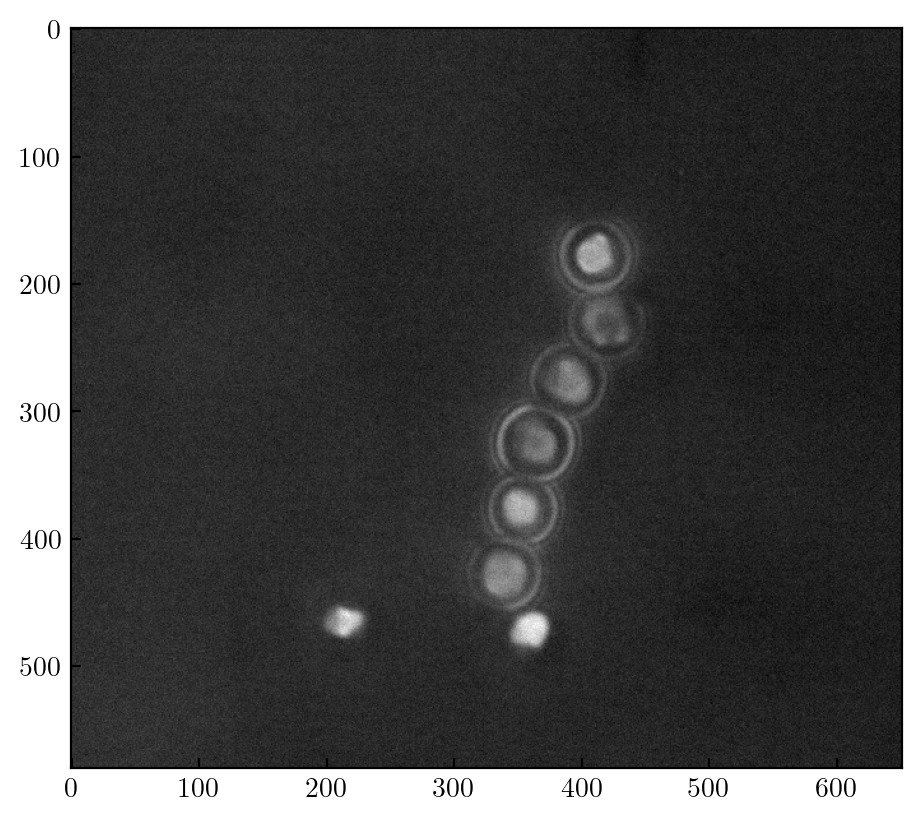

In [161]:
i = 1
plt.imshow(stack[i])

In [162]:
# for i in range(0, 10, 1):
#     plt.imsave('im_' +str(i)+'.png', stack[i])

In [163]:
# plt.imsave('im_' +str(i)+'.png', stack[i])

# Test on one image

In [213]:
RING_RADIUS = 31   # px, about the LARGEST ring in the movie
RANGE_LOWER_PX = 5
RANGE_UPPER_PX = 5
MIN_SNR = 1
SMOOTHING_SIGMA = 1

In [219]:
i = 1

img = stack[i]

xsize, ysize = img.shape[::-1]

particles = locate_particles(
    img,
    RING_RADIUS,  # ring_radius: the scale for detection, crops and checks
    ring_kwargs=dict(
        min_snr=MIN_SNR,
        smoothing_sigma=SMOOTHING_SIGMA,
        range_lower_px=RANGE_LOWER_PX,
        range_upper_px=RANGE_UPPER_PX,
        # fixed_params={"a": Rr, "sigma": Sr},
    ),
    isolate=True, 
)

rows = particles_to_rows(particles, i, fps, ysize)

rows = pd.DataFrame(rows)

rows

,frame,time,xs,ys,as,sigmas,Is_max,Is,snr,xc,yc,Ac,Ic,edge_effect
0,1,0.1,364.091034,254.799465,28.157145,2.018689,14964.803885,1.339673e+07,6.415389,365.167938,255.090895,1029,14175356.0,False
1,1,0.1,354.229494,203.205835,25.325371,1.866723,9689.273456,7.214343e+06,4.428536,353.129646,203.319772,1126,22363442.0,False
2,1,0.1,411.029124,401.839985,25.742076,2.107635,10320.232495,8.818573e+06,4.194127,411.055645,401.890683,1035,23104366.0,False
3,1,0.1,389.555792,303.796565,28.103124,2.045357,6826.264594,6.179831e+06,2.873854,390.955120,303.351381,1152,18368792.0,False
4,1,0.1,421.722647,348.332131,26.370844,2.659301,4382.922180,4.840888e+06,1.851264,417.851516,350.598523,1234,15753938.0,False


In [220]:
# for _, dico in enumerate(rows):
#     for _, item in enumerate(dico):
#         if item not in ['frame', 'time', 'edge_effect']:
#             dico[item] = np.nan
# rows

In [221]:
def plot_frame_tracking(img, results, frame, px=1.0, ysize=None, ax=None,
                        plot_trajectory=True, trail_length=None, show_inner=True,
                        show_ids=True, margin=None, cmap="gray"):
    """
    Draw `img` with the ring fits, centers, inner-part COMs and particle
    IDs of `frame`, plus (optionally) each particle's trajectory so far.

    img      : 2D array, the image of that frame (e.g. stack[frame]).
    results  : DataFrame with columns frame, xs, ys, as, xc, yc and
               (after linking) particle.
    frame    : frame number, as in results["frame"].
    px       : size of one pixel in the DataFrame's units. 1.0 if results
               are still in pixels; your `px` if you already converted
               xs, ys, as, xc, yc to SI units.
    ysize    : image height in px used for the y flip (ys = ysize - y).
               Default img.shape[0], i.e. the same as in the loop.
    ax       : matplotlib Axes to draw on; a new figure if None.
    plot_trajectory : if True (default), also draw each particle's
               ring-center path up to this frame. False = only the
               particles of this frame.
    trail_length : with plot_trajectory, only the last N frames of the
               path (None = all).
    show_inner : draw the inner-part center of mass.
    show_ids : write the trackpy particle ID next to each particle.
    margin     : optional margin in px: crop the view to the particles in
               this frame plus this margin. None = whole image.

    Returns the Axes.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))
    if ysize is None:
        ysize = img.shape[0]

    def to_img(x, y):
        # DataFrame -> image pixel coordinates (undo unit conversion and y flip)
        return np.asarray(x) / px, ysize - np.asarray(y) / px

    ax.imshow(img, cmap=cmap)
    cur = results[results["frame"] == frame]
    has_id = "particle" in results.columns
    # colors = plt.get_cmap("tab10")
    colors = plt.get_cmap("RdYlBu_r")
    theta = np.linspace(0, 2 * np.pi, 200)

    for _, row in cur.iterrows():
        pid = int(row["particle"]) if has_id else None
        c = colors(pid % 10) if has_id else "lightskyblue"
        if np.isnan(row["xs"]):
            continue
        cx, cy = to_img(row["xs"], row["ys"])
        a = row["as"] / px

        # ring fit and its center
        ax.plot(cx + a * np.cos(theta), cy + a * np.sin(theta), "-", c=c, lw=1.5)
        ax.plot(cx, cy, "+", mec=c, ms=12, mew=2)

        # inner-part center of mass
        if show_inner and not np.isnan(row.get("xc", np.nan)):
            ix, iy = to_img(row["xc"], row["yc"])
            ax.plot(ix, iy, "x", mec="tab:red", ms=8, mew=1.8)

        if show_ids and has_id:
            ax.text(cx + 0.75 * a, cy - 0.75 * a, str(pid), color=c, fontsize=11,
                    fontweight="bold")

        # path of this particle up to the current frame
        if plot_trajectory and has_id:
            path = results[(results["particle"] == pid) & (results["frame"] <= frame)]
            if trail_length is not None:
                path = path[path["frame"] > frame - trail_length]
            path = path.sort_values("frame")
            tx, ty = to_img(path["xs"], path["ys"])
            ax.plot(tx, ty, "-", c=c, lw=1, alpha=0.8)

    if margin is not None and len(cur):
        xs, ys = to_img(cur["xs"], cur["ys"])
        r = (cur["as"] / px).max()
        ax.set_xlim(np.nanmin(xs) - r - margin, np.nanmax(xs) + r + margin)
        ax.set_ylim(np.nanmax(ys) + r + margin, np.nanmin(ys) - r - margin)

    # ax.set_title(f"Frame {frame}")
    ax.axis("off")
    return ax

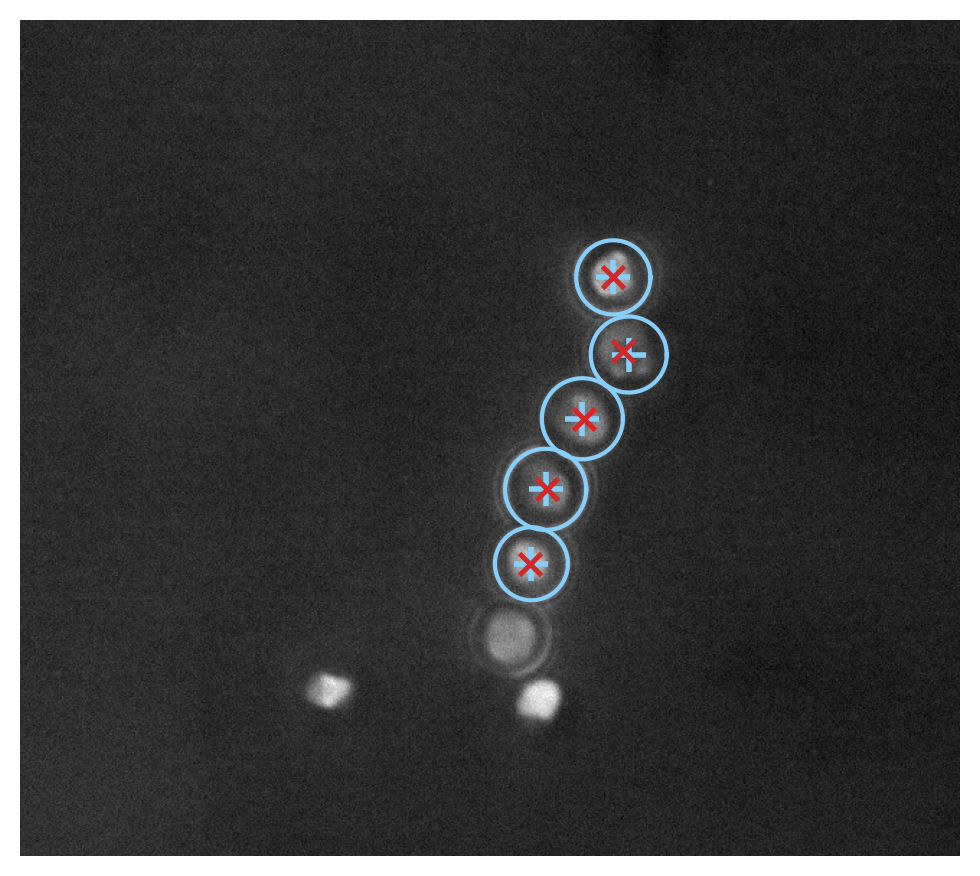

In [222]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
_ = plot_frame_tracking(img, rows, i, px=1, ysize=ysize, margin=None, plot_trajectory=False, ax=ax)
plt.tight_layout()
plt.show()

In [152]:
# fig.savefig('test.pdf', transparent=True)

In [153]:
del particles, rows

# Tracking

In [154]:
# Parameters

# Number of particles to be tracked
N_particles = 3 

# Images to track
start = 0
stop = 50
step = 1

# Number of images
Nim = math.ceil((stop - start) / step)
print(f"{Nim} images will be tracked.")

# Nim = 100 #len(stack)

# Dimensions of the images
xsize, ysize = stack[0].shape[::-1]

50 images will be tracked.


In [155]:
def tracker(stack, fps, ysize, start, stop, step, N_particles, ring_radius, min_snr, smoothing_sigma, range_lower_px, range_upper_px):
    tracked = []
    frames_with_missing_p = []
    
    for i in tqdm(range(start, stop, step)):
        img = stack[i]
        particles = locate_particles(
            img,
            RING_RADIUS,  # ring_radius: the scale for detection, crops and checks
            ring_kwargs=dict(
                min_snr=MIN_SNR,
                smoothing_sigma=SMOOTHING_SIGMA,
                range_lower_px=RANGE_LOWER_PX,
                range_upper_px=RANGE_UPPER_PX,
                # fixed_params={"a": 27, "sigma": 2},
            ),
        )
        rows = particles_to_rows(particles, i, fps, ysize)
    
        # If we miss particles, we do not keep the positions of the chain
        if len(particles) != N_particles:
            frames_with_missing_p.append(i)
            # Put NaNs
            for _, dico in enumerate(rows):
                for _, item in enumerate(dico):
                    if item not in ['frame', 'time', 'edge_effect']:
                        dico[item] = np.nan
            
        tracked += rows
        
        # Plot & save
        rows = pd.DataFrame(rows)
        fig, ax = plt.subplots(1, 1, figsize=(5, 5))
        _ = plot_frame_tracking(img, rows, i, px=1, ysize=ysize, margin=None, plot_trajectory=False, ax=ax)
        plt.tight_layout()
        fig.savefig(f'./temp/im_{i}.png')
        plt.close()
    
    tracked = pd.DataFrame(tracked)

    return tracked

In [25]:
tracked = []
frames_with_missing_p = []

for i in tqdm(range(start, stop, step)):
    img = stack[i]
    particles = locate_particles(
        img,
        RING_RADIUS,  # ring_radius: the scale for detection, crops and checks
        ring_kwargs=dict(
            min_snr=MIN_SNR,
            smoothing_sigma=SMOOTHING_SIGMA,
            range_lower_px=RANGE_LOWER_PX,
            range_upper_px=RANGE_UPPER_PX,
            # fixed_params={"a": 27, "sigma": 2},
        ),
    )
    rows = particles_to_rows(particles, i, fps, ysize)

    # If we miss particles, we do not keep the positions of the chain
    if len(particles) != N_particles:
        frames_with_missing_p.append(i)
        # Put NaNs
        for _, dico in enumerate(rows):
            for _, item in enumerate(dico):
                if item not in ['frame', 'time', 'edge_effect']:
                    dico[item] = np.nan
        
    tracked += rows
    
    # Plot & save
    rows = pd.DataFrame(rows)
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    _ = plot_frame_tracking(img, rows, i, px=1, ysize=ysize, margin=None, plot_trajectory=False, ax=ax)
    plt.tight_layout()
    fig.savefig(f'./temp/im_{i}.png')
    plt.close()

tracked = pd.DataFrame(tracked)

del particles, rows, img

100%|███████████████████████████████████████████| 50/50 [01:55<00:00,  2.31s/it]


In [26]:
# tracking did not work on those frames:
print('Frames in which less particles were found:')
print(frames_with_missing_p)
print('Percentage of missed frames = {} %'.format(int(len(frames_with_missing_p) / Nim * 100)))

Frames in which less particles were found:
[38, 39, 40, 41, 42, 43, 45]
Percentage of missed frames = 14 %


In [27]:
# Save a mp4 video with the tracked particles
# Same folder as the initial video

fps_bis = 5

path2savebis = path2save[:path2save.find('trajectories_')] + 'tracking_' + path2save[path2save.find('trajectories_')+len('trajectories_'):]
path2savebis += '.mp4'
path2savebis

# Command doing the job
!python im2mp4.py {'./temp/'} {path2savebis} --fps {fps_bis}

['temp/im_0.png', 'temp/im_1.png', 'temp/im_2.png', 'temp/im_3.png', 'temp/im_4.png', 'temp/im_5.png', 'temp/im_6.png', 'temp/im_7.png', 'temp/im_8.png', 'temp/im_9.png', 'temp/im_10.png', 'temp/im_11.png', 'temp/im_12.png', 'temp/im_13.png', 'temp/im_14.png', 'temp/im_15.png', 'temp/im_16.png', 'temp/im_17.png', 'temp/im_18.png', 'temp/im_19.png']
Wrote 50 frame(s) at 5.0 fps -> /home/nfares/postdoc/experiments/data/Rattler/20261006_rattler_diffusing_in_dextran/chain/tracking_fluto_fps_10Hz_calib_44nm_light_440nm_intensity_50percent_fps_10Hz_px_44nm.mp4


In [28]:
# Remove pictures from the folder temp
from pathlib import Path
folder = Path("./temp/")
for file in folder.glob("*"):
    file.unlink()

# Linking

In [29]:
# Linking of trajectories

# Drop Nans
features = tracked.dropna(subset=["xs"])

# Linking
linked = link_trajectories(features, search_range=15, memory=10) # in px, before conversion

# Put back NaNs
def add_nan_frames(g):
    pid = g.name
    frames = range(g["frame"].min(), g["frame"].max() + 1)
    g = g.set_index("frame").reindex(frames).rename_axis("frame")
    g["particle"] = pid  # keep the particle ID on NaN rows
    return g.reset_index()
results = linked.groupby("particle", group_keys=False).apply(add_nan_frames)

# Sort according to frame number, and particle ids
results = results.sort_values(["frame", "particle"]).reset_index(drop=True)

del features

Frame 49: 3 trajectories present.


In [40]:
p_ids = results['particle'].unique()
p_ids

array([0, 1, 2])

In [33]:
linked.head(10)

,frame,time,xs,ys,as,sigmas,Is_max,Is,snr,xc,yc,Ac,Ic,edge_effect,particle
0,0,0.0,220.558645,256.671160,27.351446,2.097721,14366.444699,1.298217e+07,4.855489,221.056389,263.702567,650.0,12642779.0,False,0
1,0,0.0,171.677558,233.732845,26.964300,2.169033,11647.727799,1.072917e+07,3.316318,169.675719,235.345725,1141.0,25198204.0,False,1
2,0,0.0,265.751779,289.222120,28.177220,1.852753,11203.674231,9.211828e+06,3.260867,266.731381,292.645346,1112.0,25437497.0,False,2
3,1,0.1,221.274381,257.569374,27.253119,1.886555,13643.764975,1.104815e+07,4.538814,221.609771,264.756010,663.0,12663766.0,False,0
4,1,0.1,268.056613,285.042631,28.088003,2.044503,12921.326579,1.168653e+07,3.980774,269.609989,287.729259,1108.0,25732691.0,False,2
5,1,0.1,172.367529,237.830704,27.259012,1.853336,11978.772089,9.531172e+06,3.709543,168.756591,242.212567,963.0,19119189.0,False,1
6,2,0.2,222.299268,256.511212,27.359501,1.983532,14861.873530,1.270255e+07,4.966884,222.210973,264.235298,617.0,12187007.0,False,0
7,2,0.2,269.831026,282.558118,28.401770,1.874253,14053.697783,1.178240e+07,4.306902,271.186798,286.056590,1074.0,21961299.0,False,2
8,2,0.2,172.537025,238.126675,27.383150,1.888432,13665.220649,1.112939e+07,4.219525,169.251589,242.711008,960.0,18809986.0,False,1
9,3,0.3,221.801291,257.671626,27.368582,2.201778,14431.118577,1.369606e+07,4.897242,221.539158,265.316829,688.0,13498661.0,False,0


In [34]:
results.head(10)

,frame,time,xs,ys,as,sigmas,Is_max,Is,snr,xc,yc,Ac,Ic,edge_effect,particle
0,0,0.0,220.558645,256.671160,27.351446,2.097721,14366.444699,1.298217e+07,4.855489,221.056389,263.702567,650.0,12642779.0,False,0
1,0,0.0,171.677558,233.732845,26.964300,2.169033,11647.727799,1.072917e+07,3.316318,169.675719,235.345725,1141.0,25198204.0,False,1
2,0,0.0,265.751779,289.222120,28.177220,1.852753,11203.674231,9.211828e+06,3.260867,266.731381,292.645346,1112.0,25437497.0,False,2
3,1,0.1,221.274381,257.569374,27.253119,1.886555,13643.764975,1.104815e+07,4.538814,221.609771,264.756010,663.0,12663766.0,False,0
4,1,0.1,172.367529,237.830704,27.259012,1.853336,11978.772089,9.531172e+06,3.709543,168.756591,242.212567,963.0,19119189.0,False,1
5,1,0.1,268.056613,285.042631,28.088003,2.044503,12921.326579,1.168653e+07,3.980774,269.609989,287.729259,1108.0,25732691.0,False,2
6,2,0.2,222.299268,256.511212,27.359501,1.983532,14861.873530,1.270255e+07,4.966884,222.210973,264.235298,617.0,12187007.0,False,0
7,2,0.2,172.537025,238.126675,27.383150,1.888432,13665.220649,1.112939e+07,4.219525,169.251589,242.711008,960.0,18809986.0,False,1
8,2,0.2,269.831026,282.558118,28.401770,1.874253,14053.697783,1.178240e+07,4.306902,271.186798,286.056590,1074.0,21961299.0,False,2
9,3,0.3,221.801291,257.671626,27.368582,2.201778,14431.118577,1.369606e+07,4.897242,221.539158,265.316829,688.0,13498661.0,False,0


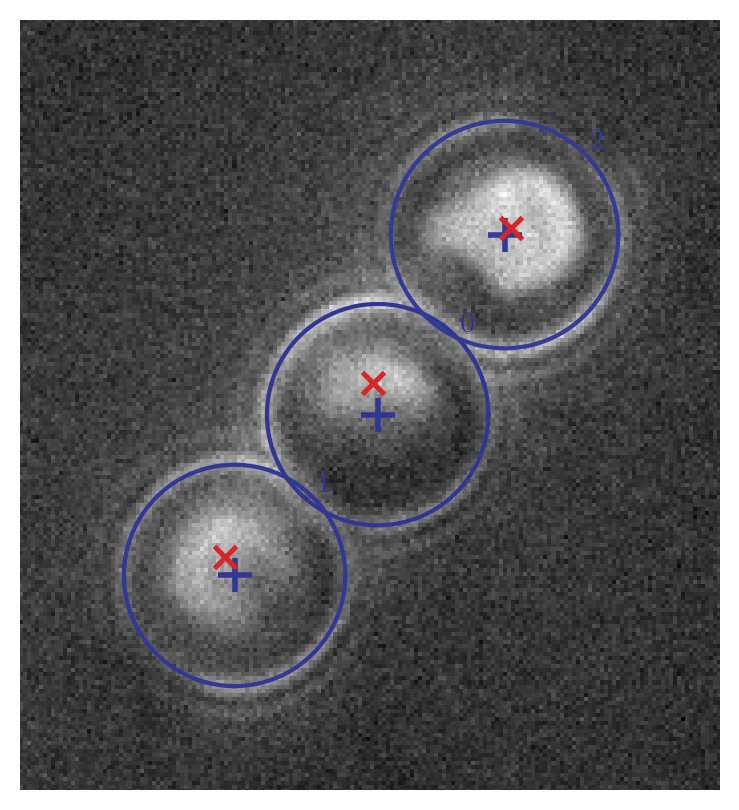

In [38]:
# Plot one image
i = 35
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
_ = plot_frame_tracking(stack[i], results, i, px=1, ysize=ysize, margin=25, plot_trajectory=False, ax=ax)
plt.show()

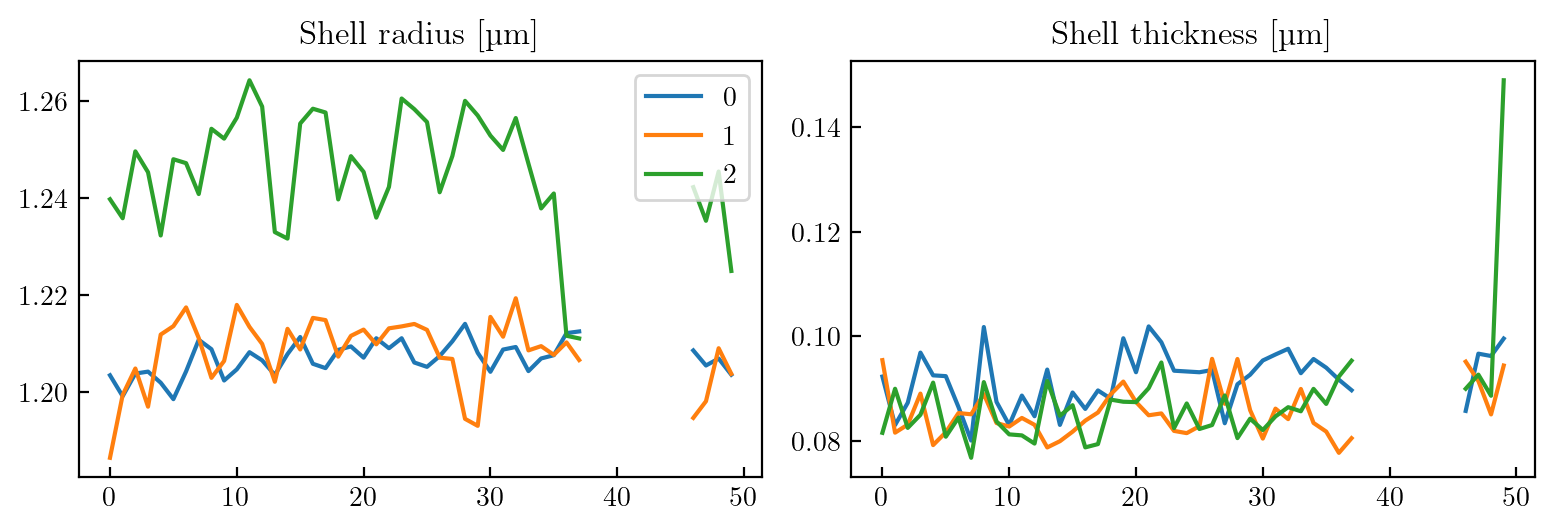

In [41]:
fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(20/2.54, 7/2.54))

for i, p in enumerate(p_ids):
    subset = results[results["particle"] == p]
    ax1.plot(subset['frame'], subset['as'] * px * 1e6, label=str(p))
    ax2.plot(subset['frame'], subset['sigmas'] * px * 1e6, label=str(p))
# ax1.plot(np.arange(len(Router[cond])), Router[cond], ls='-', c='tab:blue')
# ax1.fill_between(np.arange(len(Router[cond])), Router[cond] - Souter[cond], Router[cond]+Souter[cond], color='tab:red', alpha=0.1)

# ax2.plot(Souter[cond], ls='-', c='tab:red')

ax1.legend()

ax1.set_title(r'Shell radius [µm]')
ax2.set_title(r'Shell thickness [µm]')

plt.tight_layout()
plt.show()

In [166]:
# fig.savefig('radii_without_uint8_conversion.pdf')

In [ ]:
# Warning: run next 2 cells only once...

In [ ]:
# Conversion to SI
for col in ("xs", "ys", "as", "sigmas", "xc", "yc"):
    results[col] = results[col] * px
results["Ac"] = results["Ac"] * px ** 2

In [167]:
# Save
if not(already_saved):
    results.to_csv(path2save + '.csv', index=False)
    already_save = True

# Quick analysis

In [168]:
colors = ['tab:blue', 'tab:red', 'tab:green', 'cornerflowerblue', 'sandybrown']

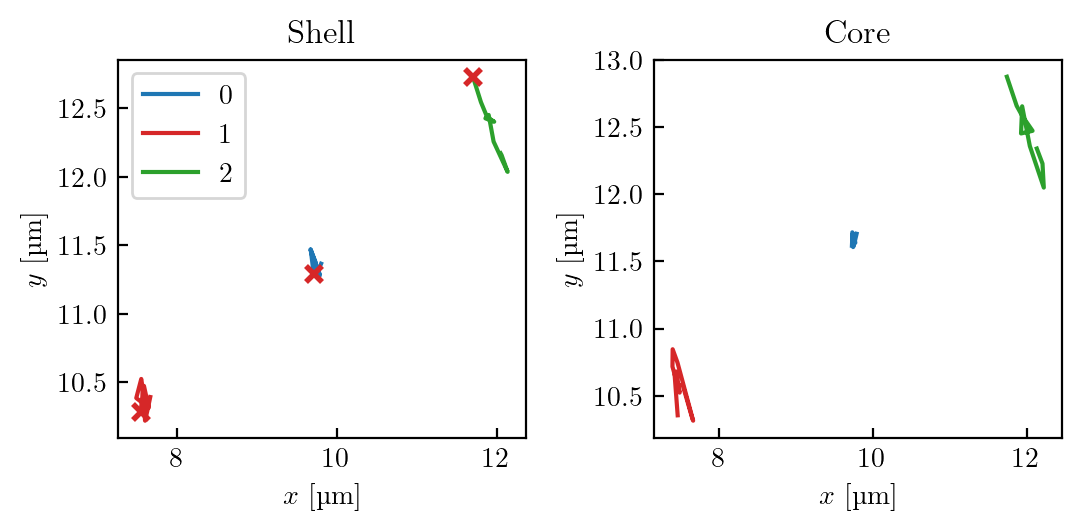

In [169]:
fig, [ax1, ax2] = plt.subplots(1, 2, figsize=(14/2.54, 7/2.54))

# start = 0
# stop = -1
# step = 1

for i, p in enumerate(p_ids):
    subset = results[results["particle"] == p]
    ax1.plot(subset['xs'] * 1e6, subset['ys'] * 1e6, color=colors[i], label=str(p))
    ax1.plot(subset['xs'].iloc[0] * 1e6, subset['ys'].iloc[0] * 1e6, 'x', mew=2, mec='tab:red')
    ax2.plot(subset['xc'] * 1e6, subset['yc'] * 1e6, color=colors[i], label=str(p))

ax1.legend()

ax1.set(xlabel=r'$x$ [\textmu m]', ylabel=r'$y$ [\textmu m]', title='Shell')
ax2.set(xlabel=r'$x$ [\textmu m]', ylabel=r'$y$ [\textmu m]', title='Core')

plt.tight_layout()
plt.show()

In [134]:
def moment(n, x, t, return_std = False, retrieve_mean = False, mean_abs = False):
    """
    Parameters
    ----------
    n: int, moment of order n
    x: array containing the values of interest
    t: an array containing differences of indexes.
    """
    res = np.zeros(len(t))
    std = np.zeros(len(t))
    for i, j in enumerate(t):
        #x_tau = x[j:] - np.mean(x[j:])
        #x_zer = x[0:-j] - np.mean(x[0:-j])
        #res[i] = np.nanmean((x_tau - x_zer)**n)
        Delta_x = x[j:] - x[0:-j]
        if retrieve_mean:
            distribution = (Delta_x - np.mean(Delta_x)) ** n
        else:
            distribution = (Delta_x) ** n
        if mean_abs:
            distribution = np.abs(distribution)
        res[i] = np.nanmean(distribution)
        std[i] = np.nanstd(distribution)
    if return_std:
        return res, std
    else:
        return res

In [135]:
print(fps)

10


In [136]:
# Define time lags
dframes = np.concatenate((np.arange(1, 10, 1), np.arange(10, 100, 2), np.arange(100, 500, 5)))
dtimes = dframes / fps

In [137]:
# Compute MSDs

MSDs = np.zeros((len(dframes), 4, N_particles)) * np.nan
# arrays with 3 dimensions
# first: value
# which MSD: 0 = shell | 1 = core | 2 = relative (radial)

for i, p in enumerate(p_ids):
    subset = results[results["particle"] == p]
    xs = subset['xs'].to_numpy()
    ys = subset['ys'].to_numpy()
    xc = subset['xc'].to_numpy()
    yc = subset['yc'].to_numpy()
    r = np.sqrt((xc - xs) ** 2 + (yc - ys) ** 2)
    shellx = moment(2, xs, dframes)
    shelly = moment(2, ys, dframes)
    shell = (shellx + shelly) / 2
    corex = moment(2, xc, dframes)
    corey = moment(2, yc, dframes)
    core = (corex + corey) / 2
    relatx = moment(2, xc - xs, dframes)
    relaty = moment(2, yc - ys, dframes)
    relat = (relatx + relaty) / 2
    MSDs[:,0,p] = dtimes
    MSDs[:,1,p] = shell
    MSDs[:,2,p] = core
    MSDs[:,3,p] = relat

/tmp/ipykernel_15266/1172535772.py:22: RuntimeWarning: Mean of empty slice
  res[i] = np.nanmean(distribution)
/home/nfares/miniforge3/envs/trackpy/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


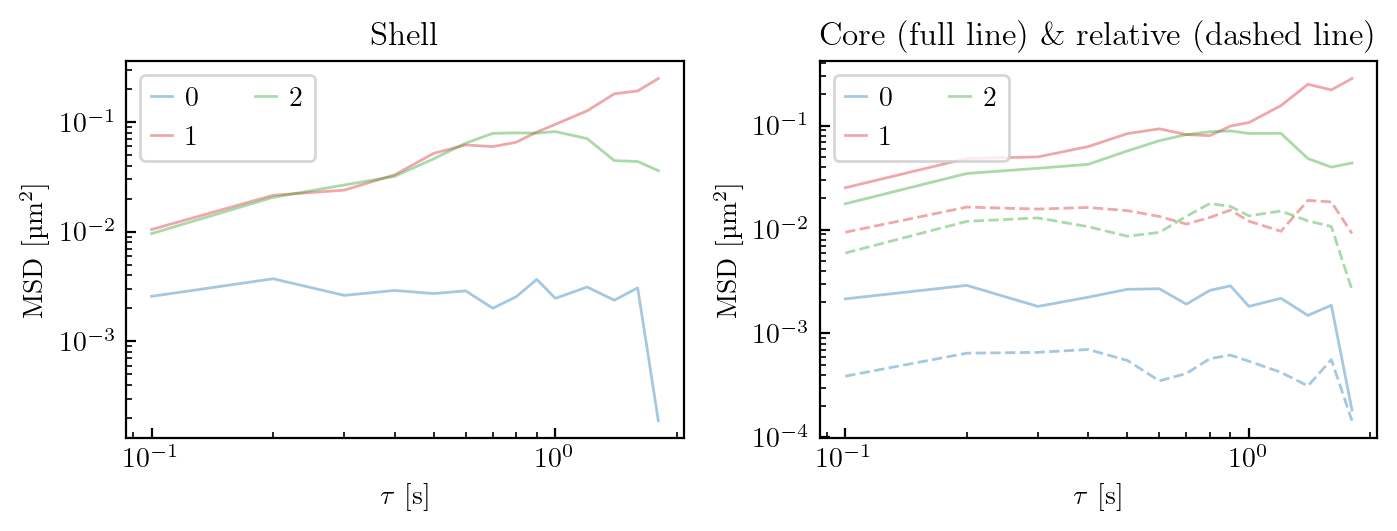

In [138]:
fig = plt.figure(figsize=(18/2.54, 7/2.54))

nlin = 1
ncol = 2
ax1 = fig.add_subplot(nlin, ncol, 1)
ax2 = fig.add_subplot(nlin, ncol, 2)

# ====================================================================================================
# === msds
# ===================================

for i, p in enumerate(p_ids):
    ax1.plot(MSDs[:,0,i], MSDs[:,1,i] * 1e12, ls='-', c=colors[i], alpha=0.4, lw=1, label=str(p))
    ax2.plot(MSDs[:,0,i], MSDs[:,2,i] * 1e12, ls='-', c=colors[i], alpha=0.4, lw=1, label=str(p))
    ax2.plot(MSDs[:,0,i], MSDs[:,3,i] * 1e12, ls='--', c=colors[i], alpha=0.4, lw=1)


ax.plot(dtimes[:-2], 2 * 0.36 * (4e-21) / (6*np.pi*0.001*1e-6) * dtimes[:-2] * 1e12, ls='--', c='k')

# ====================================================================================================
# === labels
# ===================================

ax1.legend(loc='upper left', ncol=2, handlelength=0.75, handletextpad=0.5)
ax1.set(xlabel=r'$\tau$ [s]', ylabel=r'MSD [\textmu$\mathrm{m^2}$]', xscale='log', yscale='log', title='Shell')
ax2.legend(loc='upper left', ncol=2, handlelength=0.75, handletextpad=0.5)
ax2.set(xlabel=r'$\tau$ [s]', ylabel=r'MSD [\textmu$\mathrm{m^2}$]', xscale='log', yscale='log', title=r'Core (full line) \& relative (dashed line)')


plt.tight_layout()
plt.show()

In [121]:
def pdf(data, bins=10, density=True, range=None):
    pdf, bins_edge = np.histogram(
        data, 
        bins=bins, 
        density=density, 
        range=range, 
    )
    bins_center = (bins_edge[0:-1] + bins_edge[1:]) / 2
    return pdf, bins_center